# Group 15 – Quantum Error Correction
Repetition codes (3, 5, 7 data qubits) vs an unencoded baseline under bit-flip / phase-flip channels
(p = 0.1 %, 1 %, 2 %) and the N0 / N1 / N2 noise models. 1024 shots × 5 independent seeds per configuration.

Files: `qec.py` (circuits, noise models, metrics) · `run_experiments.py` (all runs → `results/`) ·
`make_figures.py` (all plots → `figures/`).

In [1]:
import platform, numpy as np, pandas as pd, qiskit, qiskit_aer
print("Python     ", platform.python_version())
print("Qiskit     ", qiskit.__version__)
print("Qiskit Aer ", qiskit_aer.__version__)
print("NumPy      ", np.__version__, "| pandas", pd.__version__)
from qec import *
print("Shots per run:", SHOTS, "| trials:", TRIALS, "| channel p:", CHANNEL_P)
print("Noise models:", NOISE_LEVELS)

Python      3.11.15
Qiskit      2.5.2
Qiskit Aer  0.17.2
NumPy       2.4.4 | pandas 3.0.2
Shots per run: 1024 | trials: 5 | channel p: [0.001, 0.01, 0.02]
Noise models: {'N0': None, 'N1': {'p1': 0.001, 'p2': 0.005, 'ro': 0.01}, 'N2': {'p1': 0.01, 'p2': 0.02, 'ro': 0.03}}


## Noise model (depolarizing + readout) attached to AerSimulator

In [2]:
import inspect
print(inspect.getsource(build_noise_model))
print(inspect.getsource(run_counts))

def build_noise_model(level):
    """Return an Aer NoiseModel for N1/N2 (None for the ideal N0 case)."""
    cfg = NOISE_LEVELS[level]
    if cfg is None:
        return None
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(cfg["p1"], 1), ["h", "x", "z"])
    nm.add_all_qubit_quantum_error(depolarizing_error(cfg["p2"], 2), ["cx"])
    ro = cfg["ro"]
    nm.add_all_qubit_readout_error(ReadoutError([[1 - ro, ro], [ro, 1 - ro]]))
    return nm

def run_counts(qc, noise_level="N0", seed=11, shots=SHOTS):
    sim = AerSimulator(noise_model=build_noise_model(noise_level), seed_simulator=seed)
    return sim.run(qc, shots=shots).result().get_counts()



## Rep-3 bit-flip code circuit

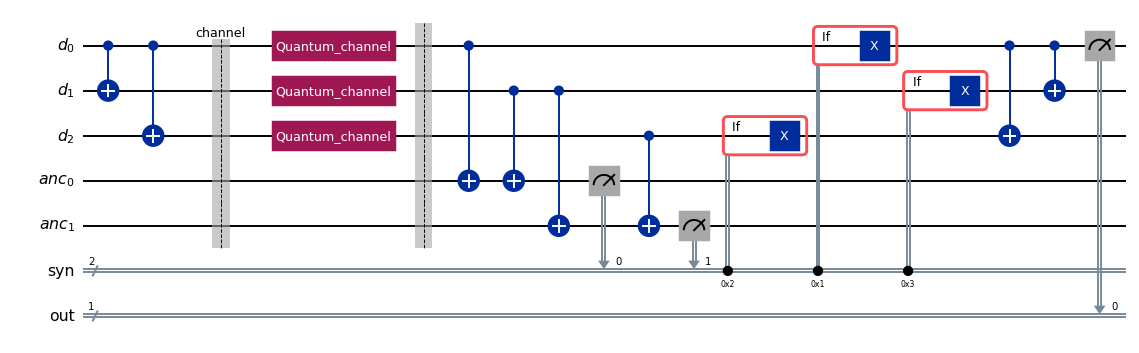

In [3]:
build(3, "bit", 0.02).draw("mpl", fold=-1, scale=0.7)

## A successful run: Rep-3 vs unencoded, bit-flip channel p = 2 %, N1 noise, 5 seeds

In [4]:
rows = []
for name, d, ro in [("Unencoded", 1, "decode"), ("Rep-3 decode", 3, "decode"), ("Rep-3 majority", 3, "majority")]:
    lers = [metrics(run_counts(build(d, "bit", 0.02, readout=ro), "N1", seed=seed_for(9, d, len(ro), t)))["ler"]
            for t in range(TRIALS)]
    rows.append(dict(config=name, ler_mean=np.mean(lers), ler_sd=np.std(lers, ddof=1), per_seed=np.round(lers, 4).tolist()))
pd.DataFrame(rows)

,config,ler_mean,ler_sd,per_seed
0,Unencoded,0.029102,0.004389,"[0.0254, 0.0352, 0.0254, 0.0273, 0.0322]"
1,Rep-3 decode,0.033789,0.004663,"[0.0303, 0.0371, 0.0371, 0.0371, 0.0273]"
2,Rep-3 majority,0.011328,0.003134,"[0.0117, 0.0068, 0.0098, 0.0137, 0.0146]"


## Sample output: one run's measurement counts ('logical syndrome')

In [5]:
counts = run_counts(build(3, "bit", 0.02), "N0", seed=seed_for(9, 0))
print(dict(sorted(counts.items(), key=lambda kv: -kv[1])))
print(metrics(counts))

{'0 00': 962, '0 10': 22, '0 11': 20, '0 01': 19, '1 11': 1}
{'ler': 0.0009765625, 'detected': 62, 'detected_ok': 61, 'shots': 1024}


## Summary of the full experiment grid (from results/grid_summary.csv)

In [6]:
g = pd.read_csv("results/grid_summary.csv")
t = g[(g.kind == "bit") & (g.p == 0.02)].copy()
t["LER (mean ± SD)"] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(t.ler_mean, t.ler_sd)]
t.pivot_table(index=["code", "readout"], columns="noise", values="LER (mean ± SD)", aggfunc="first")

noise                       N0               N1               N2
code readout                                                    
1    none      0.0195 ± 0.0052  0.0307 ± 0.0061  0.0568 ± 0.0059
3    decode    0.0010 ± 0.0007  0.0320 ± 0.0077  0.0992 ± 0.0070
     majority  0.0004 ± 0.0005  0.0080 ± 0.0030  0.0350 ± 0.0075
5    decode    0.0000 ± 0.0000  0.0531 ± 0.0088  0.1508 ± 0.0059
     majority  0.0000 ± 0.0000  0.0105 ± 0.0031  0.0432 ± 0.0063
7    decode    0.0000 ± 0.0000  0.0631 ± 0.0065  0.1992 ± 0.0210
     majority  0.0000 ± 0.0000  0.0158 ± 0.0030  0.0549 ± 0.0071